# SampaIA — Em quanto tempo um pedido de zeladoria do SP156 é atendido?

**Pergunta:** quando um cidadão abre um pedido de zeladoria no SP156 (buraco, entulho, árvore, bueiro, varrição), em quanto tempo ele deve ser atendido?
**Resposta no app:** "pedidos como o seu costumam levar de 8 a 30 dias".

**Alvo (3 classes):** até 7 dias · 8 a 30 dias · mais de 30 dias, calculado entre *Data de Abertura* e *Data de Finalização*.

**Dados reais:** [Dados do SP156 — Portal de Dados Abertos da Prefeitura de São Paulo](https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156), licença CC0, já sem dados pessoais. Recorte: 3º trimestre de 2025 ao 2º trimestre de 2026 (ver `dados/README.md`).

**Modelo:** rede neural MLP em PyTorch, comparada com uma Regressão Logística como linha de base.

## 0. Ambiente

Executado no Google Colab (GPU T4). Na primeira execução da sessão a célula abaixo baixa os 4 CSVs direto do portal da Prefeitura (cerca de 10 minutos); nesta execução eles já estavam na sessão.

In [1]:
import sys
from pathlib import Path

NO_COLAB = "google.colab" in sys.modules
# No Colab: preparar.py e baixar_dados.py são enviados para a pasta do notebook; os CSVs vêm do portal.
if NO_COLAB and not any(Path("dados").glob("*.csv*")):
    Path("dados").mkdir(exist_ok=True)
    !python baixar_dados.py
Path("prints").mkdir(exist_ok=True)
print(sorted(p.name for p in Path("dados").glob("*.csv*")))

['arquivo-final-1-trim-26.csv', 'arquivo-final-2-trim-26.csv', 'arquivo-final-3-trim-25.csv', 'arquivo-final-4-trim-25.csv']


In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, recall_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

from preparar import FAIXAS, FAIXAS_TEXTO, RedePrazo, carregar, codificar, preparar

SEMENTE = 42
device = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.width", 140)
print(device)

cuda


## 1. Carregar e preparar

In [3]:
bruto = carregar()
dados = preparar(bruto)
print(f"Pedidos no recorte: {len(bruto):,}")
print(f"Pedidos de zeladoria finalizados usados: {len(dados):,}")
print(f"Período de abertura: {dados.abertura.min():%d/%m/%Y} a {dados.abertura.max():%d/%m/%Y}")
dados.head()

Pedidos no recorte: 2,023,061
Pedidos de zeladoria finalizados usados: 373,838
Período de abertura: 01/07/2025 a 30/06/2026


,categoria,subprefeitura,distrito,canal,mes,dia_semana,abertura,dias,faixa
0,bueiro,M BOI MIRIM,JARDIM ANGELA,CRM,1,3,2026-01-01,20,8a30
1,arvore,VILA MARIANA,VILA MARIANA,MOBILE,1,3,2026-01-01,35,mais30
2,bueiro,SAO MIGUEL,SAO MIGUEL,CHATBOT,1,3,2026-01-01,28,8a30
3,arvore,FREGUESIA-BRASILANDIA,FREGUESIA DO O,PORTAL,1,3,2026-01-01,13,8a30
4,arvore,LAPA,PERDIZES,PORTAL,1,3,2026-01-01,84,mais30


**Limpeza aplicada** (em `preparar.py`, o mesmo código usado pelo serviço): só serviços de zeladoria; só pedidos com status *Finalizada* e com as duas datas válidas; tempo negativo descartado; textos padronizados em maiúsculas. Endereço, CEP e coordenadas **não** são usados.

**Variáveis:** tipo do pedido, subprefeitura, distrito, canal de abertura (portal, app, telefone...), mês e dia da semana da abertura.

## 2. Exploração

In [4]:
print(dados["faixa"].value_counts(normalize=True).reindex(FAIXAS).round(3).rename(index=FAIXAS_TEXTO))
dados.groupby("categoria")["dias"].agg(["count", "median", lambda s: s.quantile(0.9)]).rename(columns={"<lambda_0>": "p90"})

faixa
até 7 dias         0.728
8 a 30 dias        0.162
mais de 30 dias    0.110
Name: proportion, dtype: float64


,count,median,p90
categoria,,,
arvore,81273,17.0,99.0
bueiro,22233,1.0,16.0
buraco,86033,6.0,32.0
entulho,151509,1.0,4.0
varricao,32790,1.0,4.0


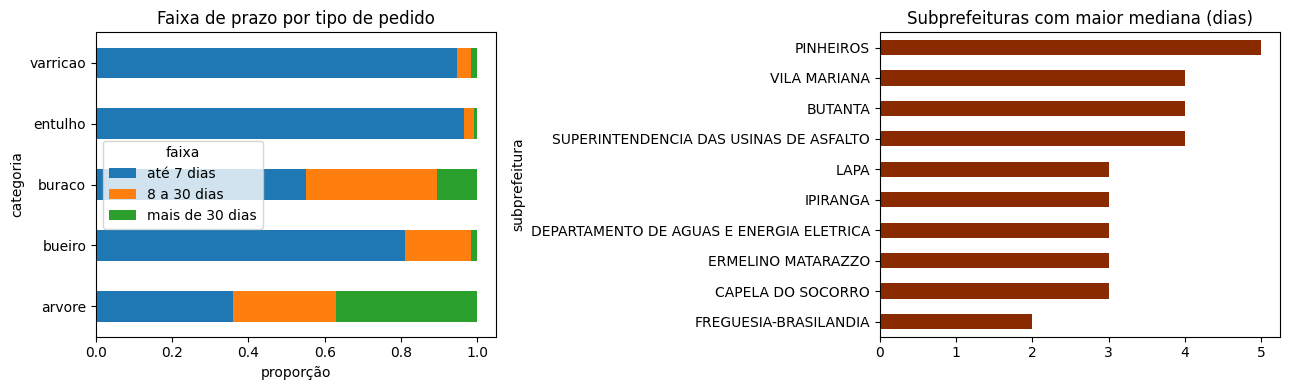

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(dados.groupby("categoria")["faixa"].value_counts(normalize=True).unstack()[FAIXAS]
     .rename(columns=FAIXAS_TEXTO).plot.barh(stacked=True, ax=ax[0], title="Faixa de prazo por tipo de pedido"))
ax[0].set_xlabel("proporção")
dados.groupby("subprefeitura")["dias"].median().sort_values().tail(10).plot.barh(
    ax=ax[1], title="Subprefeituras com maior mediana (dias)", color="#8a2a00")
plt.tight_layout(); plt.savefig("prints/ml-exploracao.png", dpi=110); plt.show()

As classes são desbalanceadas: a maioria dos pedidos fecha em até 7 dias. Um modelo que chutasse sempre "até 7 dias" acertaria 73% sem aprender nada. Por isso:
- a métrica principal é o **recall macro** (média do recall das três faixas: cada faixa pesa igual);
- os modelos são treinados com **peso por classe** (classes raras pesam mais no erro).

## 3. Divisão treino/teste (80/20 estratificada) e padronização

In [6]:
y = dados["faixa"].map({f: i for i, f in enumerate(FAIXAS)}).to_numpy()
dados_treino, dados_teste, y_treino, y_teste = train_test_split(dados, y, test_size=0.2, stratify=y, random_state=SEMENTE)

# Colunas 0/1 aprendidas só no treino; o teste é alinhado a elas.
X_treino = codificar(dados_treino)
colunas = list(X_treino.columns)
X_teste = codificar(dados_teste, colunas)

scaler = StandardScaler()
X_treino = scaler.fit_transform(X_treino)
X_teste = scaler.transform(X_teste)
print("treino:", X_treino.shape, "teste:", X_teste.shape)

treino: (299070, 149) teste: (74768, 149)


## 4. Linha de base: Regressão Logística

In [7]:
def metricas(nome, prever):
    linhas = []
    for base, X, y_real in [("treino", X_treino, y_treino), ("teste", X_teste, y_teste)]:
        p = prever(X)
        linhas.append({"modelo": nome, "base": base, "acurácia": accuracy_score(y_real, p), "recall macro": recall_score(y_real, p, average="macro")})
    return pd.DataFrame(linhas)

logistica = LogisticRegression(max_iter=5000, class_weight="balanced")
logistica.fit(X_treino, y_treino)
res_log = metricas("Regressão Logística", logistica.predict)
res_log.round(3)

,modelo,base,acurácia,recall macro
0,Regressão Logística,treino,0.676,0.659
1,Regressão Logística,teste,0.674,0.657


## 5. Rede neural (MLP)

Duas camadas ocultas com `relu` e `Dropout`, saída com 3 neurônios (uma por faixa). A última camada **não** tem ativação: o `CrossEntropyLoss` já espera os valores crus.

Treino em lotes de 1024 pedidos com `DataLoader`: o `DataLoader` sorteia os índices dos pedidos de cada lote.

In [8]:
def treinar(X, y, oculta, lr, epocas, X_val=None, y_val=None):
    torch.manual_seed(SEMENTE)
    peso = torch.tensor(len(y) / (3 * np.bincount(y)), dtype=torch.float32).to(device)  # mesma conta do class_weight='balanced'
    criterion = nn.CrossEntropyLoss(weight=peso)
    rede = RedePrazo(X.shape[1], oculta).to(device)
    optimizer = optim.Adam(rede.parameters(), lr=lr)
    X_t = torch.tensor(X, dtype=torch.float32).to(device)
    y_t = torch.tensor(y).to(device)
    lotes = DataLoader(range(len(y)), batch_size=1024, shuffle=True)
    erro_treino, erro_val = [], []
    for epoca in range(epocas):
        rede.train()
        soma = 0
        for idx in lotes:
            optimizer.zero_grad()
            loss = criterion(rede(X_t[idx]), y_t[idx])
            loss.backward()
            optimizer.step()
            soma += loss.item()
        erro_treino.append(soma / len(lotes))
        if X_val is not None:
            rede.eval()
            with torch.no_grad():
                Xv = torch.tensor(X_val, dtype=torch.float32).to(device)
                erro_val.append(criterion(rede(Xv), torch.tensor(y_val).to(device)).item())
    rede.eval()
    return rede, erro_treino, erro_val


def prever(rede, X):
    with torch.no_grad():
        return rede(torch.tensor(X, dtype=torch.float32).to(device)).argmax(1).cpu().numpy()

## 6. Busca de hiperparâmetros com validação cruzada (só no treino)

**12 combinações** de 3 hiperparâmetros: neurônios na camada oculta {16, 64, 128} × taxa de aprendizado {0,001; 0,01} × épocas {5, 15}.
Validação cruzada `StratifiedKFold` com 5 partes, **só dentro da base de treino** (o teste fica guardado até o fim). Em cada parte, as colunas 0/1 e a padronização são aprendidas só com a parte de treino daquela rodada.
Para caber no tempo, a busca usa uma amostra estratificada de 60 mil pedidos do treino; a melhor combinação depois é treinada com o treino inteiro.

In [9]:
_, amostra, _, y_amostra = train_test_split(dados_treino, y_treino, test_size=60_000, stratify=y_treino, random_state=SEMENTE)
amostra = amostra.reset_index(drop=True)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

resultados = []
for oculta in [16, 64, 128]:
    for lr in [0.001, 0.01]:
        for epocas in [5, 15]:
            rec_tr, rec_va = [], []
            for i_tr, i_va in folds.split(amostra, y_amostra):
                A = codificar(amostra.iloc[i_tr]); cols = list(A.columns)
                B = codificar(amostra.iloc[i_va], cols)
                sc = StandardScaler(); A = sc.fit_transform(A); B = sc.transform(B)
                rede, _, _ = treinar(A, y_amostra[i_tr], oculta, lr, epocas)
                rec_tr.append(recall_score(y_amostra[i_tr], prever(rede, A), average="macro"))
                rec_va.append(recall_score(y_amostra[i_va], prever(rede, B), average="macro"))
            resultados.append({"oculta": oculta, "lr": lr, "épocas": epocas,
                               "recall treino (CV)": np.mean(rec_tr), "recall validação (CV)": np.mean(rec_va), "desvio": np.std(rec_va)})
            print(resultados[-1])

grade = pd.DataFrame(resultados)
melhor = grade.loc[grade["recall validação (CV)"].idxmax()]
print("Melhor:", melhor[["oculta", "lr", "épocas"]].to_dict())
grade.sort_values("recall validação (CV)", ascending=False).round(4)

{'oculta': 16, 'lr': 0.001, 'épocas': 5, 'recall treino (CV)': np.float64(0.6672607478109535), 'recall validação (CV)': np.float64(0.6604161498391495), 'desvio': np.float64(0.007396305576918402)}
{'oculta': 16, 'lr': 0.001, 'épocas': 15, 'recall treino (CV)': np.float64(0.6892803737735603), 'recall validação (CV)': np.float64(0.676278084138288), 'desvio': np.float64(0.007883266310332983)}
{'oculta': 16, 'lr': 0.01, 'épocas': 5, 'recall treino (CV)': np.float64(0.6865395267412937), 'recall validação (CV)': np.float64(0.6754330408199747), 'desvio': np.float64(0.006888975235720537)}
{'oculta': 16, 'lr': 0.01, 'épocas': 15, 'recall treino (CV)': np.float64(0.6995768569329317), 'recall validação (CV)': np.float64(0.6848640011426044), 'desvio': np.float64(0.010328123556933855)}
{'oculta': 64, 'lr': 0.001, 'épocas': 5, 'recall treino (CV)': np.float64(0.6747298689849116), 'recall validação (CV)': np.float64(0.6663226900001598), 'desvio': np.float64(0.006644004625665286)}
{'oculta': 64, 'lr': 

,oculta,lr,épocas,recall treino (CV),recall validação (CV),desvio
7,64,0.010,15,0.7122,0.6920,0.0059
9,128,0.001,15,0.7122,0.6909,0.0078
5,64,0.001,15,0.7073,0.6902,0.0102
10,128,0.010,5,0.6995,0.6860,0.0077
11,128,0.010,15,0.7179,0.6849,0.0093
3,16,0.010,15,0.6996,0.6849,0.0103
6,64,0.010,5,0.6946,0.6816,0.0086
1,16,0.001,15,0.6893,0.6763,0.0079
2,16,0.010,5,0.6865,0.6754,0.0069
8,128,0.001,5,0.6848,0.6737,0.0067


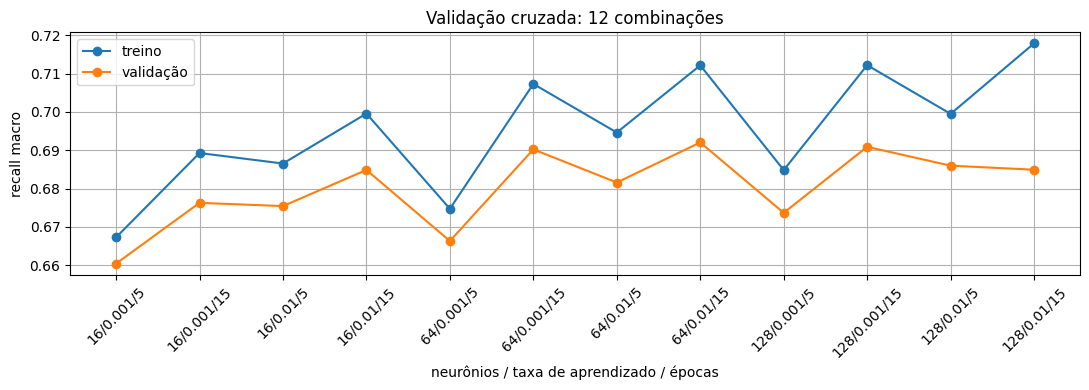

In [10]:
nomes = [f"{int(r.oculta)}/{r.lr}/{int(r['épocas'])}" for _, r in grade.iterrows()]
plt.figure(figsize=(11, 4))
plt.plot(nomes, grade["recall treino (CV)"], "o-", label="treino")
plt.plot(nomes, grade["recall validação (CV)"], "o-", label="validação")
plt.xticks(rotation=45); plt.xlabel("neurônios / taxa de aprendizado / épocas"); plt.ylabel("recall macro")
plt.title("Validação cruzada: 12 combinações"); plt.legend(); plt.grid(); plt.tight_layout(); plt.show()

**Leitura da grade:** mais épocas ajudam em todas as combinações (o modelo ainda estava aprendendo com 5). A melhor é **64 neurônios, taxa 0,01 e 15 épocas** (recall macro de validação 0,692 ± 0,006). Com 128 neurônios e taxa 0,01 o treino sobe (0,718) mas a validação cai (0,685): começo de overfitting, a rede maior decora a amostra. A distância treino × validação fica entre 0,007 e 0,033 em todas as combinações.

## 7. Treino final com a melhor combinação e curva de erro (overfitting?)

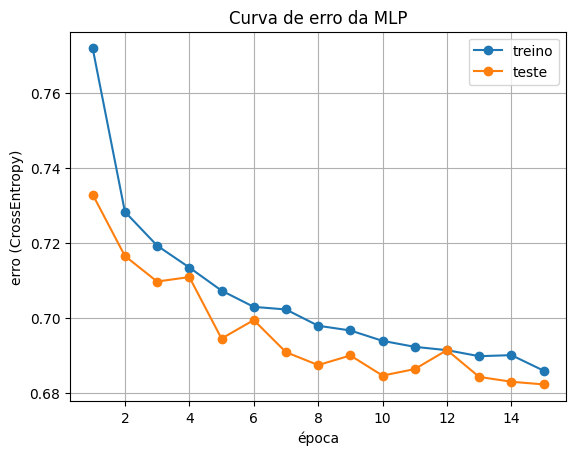

In [11]:
oculta, lr, epocas = int(melhor.oculta), float(melhor.lr), int(melhor["épocas"])
rede, erro_treino, erro_teste = treinar(X_treino, y_treino, oculta, lr, epocas, X_teste, y_teste)

plt.plot(range(1, epocas + 1), erro_treino, "o-", label="treino")
plt.plot(range(1, epocas + 1), erro_teste, "o-", label="teste")
plt.xlabel("época"); plt.ylabel("erro (CrossEntropy)"); plt.title("Curva de erro da MLP"); plt.legend(); plt.grid()
plt.savefig("prints/ml-curva-aprendizado.png", dpi=110); plt.show()

**Overfitting?** Não. Os erros de treino e de teste caem juntos e ficam próximos até a última época (0,686 × 0,682). O erro de teste fica um pouco abaixo do de treino porque o `Dropout` desliga 20% dos neurônios durante o treino (e o erro de treino é a média ao longo da época); no teste a rede usa todos. Na validação cruzada, 15 épocas foram melhores que 5 em todas as combinações; mais épocas poderiam dar um ganho pequeno.

## 8. Resultados em treino e teste, lado a lado

In [12]:
res_mlp = metricas("MLP", lambda X: prever(rede, X))
comparacao = pd.concat([res_log, res_mlp]).pivot(index="modelo", columns="base", values=["acurácia", "recall macro"])
comparacao.round(3)

acurácia        recall macro       
base                   teste treino        teste treino
modelo                                                 
MLP                    0.681  0.685        0.705  0.710
Regressão Logística    0.674  0.676        0.657  0.659

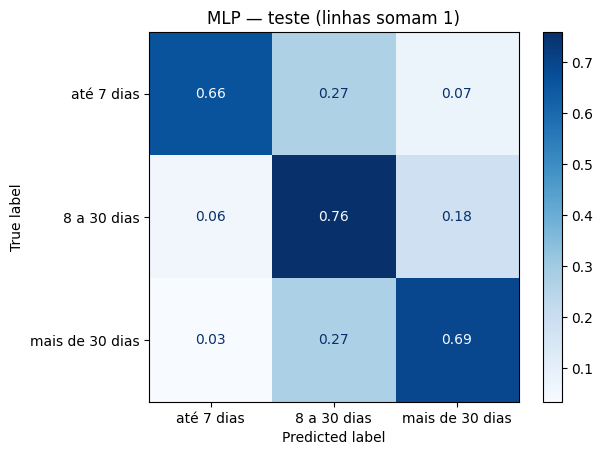

                 precision    recall  f1-score   support

     até 7 dias      0.973     0.662     0.788     54412
    8 a 30 dias      0.354     0.759     0.483     12097
mais de 30 dias      0.484     0.693     0.570      8259

       accuracy                          0.681     74768
      macro avg      0.604     0.705     0.614     74768
   weighted avg      0.819     0.681     0.715     74768



In [13]:
pred = prever(rede, X_teste)
nomes_faixas = [FAIXAS_TEXTO[f] for f in FAIXAS]
ConfusionMatrixDisplay.from_predictions(y_teste, pred, display_labels=nomes_faixas, normalize="true", values_format=".2f", cmap="Blues")
plt.title("MLP — teste (linhas somam 1)"); plt.savefig("prints/ml-matriz-confusao.png", dpi=110, bbox_inches="tight"); plt.show()
print(classification_report(y_teste, pred, target_names=nomes_faixas, digits=3))

**Treino × teste:** a MLP ganha da Regressão Logística no teste (recall macro **0,705** contra 0,657; acurácia 0,681 contra 0,674). A diferença treino → teste é de só 0,005 na MLP: ela generaliza para pedidos que nunca viu.

**Por que a rede ganha:** a Regressão Logística soma o efeito de cada variável separadamente. A MLP combina variáveis: "árvore **em Itaquera**" demora muito mais que "árvore" e "Itaquera" sozinhos indicariam.

**Leitura da matriz:** com peso por classe, o modelo reconhece bem as três faixas (recall 0,66 / 0,76 / 0,69). A maior parte dos erros é "para cima": 27% dos pedidos que fecharam em até 7 dias foram previstos como 8 a 30 dias (para o cidadão, ouvir um prazo um pouco maior é melhor que ouvir um prazo curto que não se cumpre). O erro contrário também existe: 27% dos pedidos que passaram de 30 dias foram previstos como 8 a 30 dias, ou seja, cerca de 1 em cada 4 pedidos demorados recebe uma faixa otimista. A acurácia (0,68) fica abaixo dos 73% de "chutar sempre até 7 dias" justamente por isso: o modelo troca acertos fáceis da faixa rápida por reconhecer os pedidos demorados, que o chute nunca acerta.

## 9. Exportar o modelo para o serviço `/prever-prazo`

In [14]:
mapa_sub = dados.groupby("distrito")["subprefeitura"].agg(lambda s: s.mode().iat[0]).to_dict()
teste = res_mlp[res_mlp.base == "teste"].iloc[0]
pacote = {
    "pesos": {k: v.cpu() for k, v in rede.state_dict().items()},
    "oculta": oculta,
    "colunas": colunas,
    "media": scaler.mean_, "escala": scaler.scale_,  # números puros: o serviço padroniza sem precisar do objeto do sklearn
    "faixas": FAIXAS,
    "mapa_subprefeitura": mapa_sub,
    "metricas_teste": {"acurácia": round(float(teste["acurácia"]), 3), "recall macro": round(float(teste["recall macro"]), 3)},
    "periodo": f"{dados.abertura.min():%d/%m/%Y} a {dados.abertura.max():%d/%m/%Y}",
    "melhores_parametros": {"oculta": oculta, "lr": lr, "épocas": epocas},
}
joblib.dump(pacote, "modelo.joblib", compress=3)
print("salvo modelo.joblib", pacote["metricas_teste"])

salvo modelo.joblib {'acurácia': 0.681, 'recall macro': 0.705}


In [15]:
if NO_COLAB:  # baixa modelo + gráficos num arquivo só
    !zip -qr resultados.zip modelo.joblib prints
    from google.colab import files
    files.download("resultados.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusão para o cidadão

- **Entulho, varrição e bueiro** costumam ser resolvidos rápido (mediana de 1 dia).
- **Tapa-buraco** leva por volta de uma semana (mediana de 6 dias), e 1 em cada 10 passa de um mês.
- **Árvore** é o pedido mais demorado: mediana de 17 dias, e 1 em cada 10 passa de 99 dias.
- O modelo reconhece 7 de cada 10 pedidos demorados (mais de 30 dias) e 3 de cada 4 pedidos de 8 a 30 dias. Isso basta para dar uma **expectativa honesta** no app ("pedidos como o seu costumam levar de 8 a 30 dias"), não para prometer uma data.
- **Limites:** só entram pedidos já finalizados (os ainda abertos tendem a ser os mais demorados, então os prazos reais podem ser um pouco maiores); "finalizado" no sistema nem sempre significa problema resolvido na rua; o recorte é de um ano e pode mudar com contratos e estações do ano.